# Task 2 – History and calendar features (Maram)
**Input:** `food_clean.csv` (from `Task2_Cleaning.ipynb`, run that first)  
**Output:** `maram_features.csv`, the history and calendar columns, joined with Joud's columns at the end of the week.

In [1]:
import pandas as pd

We only need pandas here.

In [2]:
df = pd.read_csv('food_clean.csv')
df['Inspection Date'] = pd.to_datetime(df['Inspection Date'])
print(df.shape)

(126787, 20)


We read the clean file. The date becomes text again when saved to CSV, so we change it back to a real date.

In [4]:
# M1: sort each business's inspections from oldest to newest
df = df.sort_values(by=['License #', 'Inspection Date'])
df[['License #', 'Inspection Date', 'Results']].head(10)

,License #,Inspection Date,Results
121703,2.0,2015-04-21,Pass
109573,2.0,2015-12-14,Pass
104921,2.0,2016-03-22,Pass w/ Conditions
92329,2.0,2016-10-27,Fail
91797,2.0,2016-11-04,Pass
89763,2.0,2016-12-14,Pass w/ Conditions
82206,2.0,2017-05-12,Pass
68892,2.0,2018-02-13,Pass w/ Conditions
42283,2.0,2019-11-01,Pass w/ Conditions
122856,9.0,2015-03-26,Pass w/ Conditions


**M1.** We sort by License # and then by date, so the inspections of one business are next to each other, oldest first. The next steps need this order.

In [7]:
# M2: did this business fail its previous inspection?
df['Prev_Fail'] = df.groupby('License #')['Fail'].shift(1)
df[['License #', 'Inspection Date', 'Fail', 'Prev_Fail']].head(10)

,License #,Inspection Date,Fail,Prev_Fail
121703,2.0,2015-04-21,0,NaN
109573,2.0,2015-12-14,0,0.0
104921,2.0,2016-03-22,0,0.0
92329,2.0,2016-10-27,1,0.0
91797,2.0,2016-11-04,0,1.0
89763,2.0,2016-12-14,0,0.0
82206,2.0,2017-05-12,0,0.0
68892,2.0,2018-02-13,0,0.0
42283,2.0,2019-11-01,0,0.0
122856,9.0,2015-03-26,0,NaN


**M2.** `shift(1)` is new for us: it moves the column down by one row, so each inspection gets the result of the inspection before it. `groupby('License #')` makes sure it only looks inside the same business. The first inspection of each business has nothing before it, so it gets an empty value (NaN).

In [8]:
df['First_Inspection'] = df['Prev_Fail'].isnull().apply(lambda x: 1 if x else 0)
df['Prev_Fail'] = df['Prev_Fail'].fillna(0)
df['First_Inspection'].value_counts()

First_Inspection
0    101215
1     25572
Name: count, dtype: int64

We save "is this the first inspection we have for this business?" in its own column (1 = yes), then fill the empty Prev_Fail with 0. This way the model still knows which rows had no history. (Write here how many first inspections there are.)

In [9]:
# M3: days since the last inspection of the same business
df['Days_Since_Last'] = df.groupby('License #')['Inspection Date'].diff().dt.days
df['Days_Since_Last'].describe()

count    101215.000000
mean        249.509322
std         239.158985
min           1.000000
25%          13.000000
50%         236.000000
75%         375.000000
max        2564.000000
Name: Days_Since_Last, dtype: float64

**M3.** `diff()` and `.dt.days` are new for us: `diff()` subtracts the previous date from this date (inside the same business), and `.dt.days` turns the result into a number of days. First inspections have no previous date, so they are empty. (Write here the median number of days.)

In [10]:
median_days = df['Days_Since_Last'].median()
df['Days_Since_Last'] = df['Days_Since_Last'].fillna(median_days)
print(median_days)

236.0


We fill the empty values (first inspections) with the median, because the median is not affected by very long gaps. The First_Inspection column still tells the model these rows were filled.

In [11]:
# M4: month of the inspection
df['Month'] = df['Inspection Date'].dt.month
df['Month'].value_counts().sort_index()

Month
1     10333
2      9216
3     11701
4     10818
5     11599
6     11984
7      9396
8     11002
9     11054
10    11212
11     9822
12     8650
Name: count, dtype: int64

**M4.** The month (1–12). Hot months may have more temperature problems; the Chicago model also used temperature.

In [12]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['Season'] = df['Month'].apply(get_season)
df['Season'].value_counts()

Season
Spring    34118
Summer    32382
Fall      32088
Winter    28199
Name: count, dtype: int64

We group the months into seasons with a def + apply, like we did in the labs.

In [15]:
# M5: keep the 8 most common facility types, the rest becomes 'Other'
top8 = df['Facility Type'].value_counts().head(8).index
top8

Index(['Restaurant', 'Grocery Store', 'School', 'Children's Services Facility',
       'Daycare Above and Under 2 Years', 'Bakery', 'Long Term Care',
       'Daycare (2 - 6 Years)'],
      dtype='str', name='Facility Type')

In [18]:
df['Facility Type'].value_counts().head(15)

Facility Type
Restaurant                         87530
Grocery Store                      14408
School                              8822
Children's Services Facility        3915
Daycare Above and Under 2 Years     1898
Bakery                              1839
Long Term Care                      1225
Daycare (2 - 6 Years)               1096
Catering                             771
Mobile Food Preparer                 613
Liquor                               486
Hospital                             483
Golden Diner                         417
Mobile Food Dispenser                257
TAVERN                               161
Name: count, dtype: int64

**M5.** There are many facility types and most have very few rows. We keep the 8 most common ones (written above).

In [20]:
def group_facility(t):
    if t in top8:
        return t
    else:
        return 'Other'

df['Facility_Group'] = df['Facility Type'].apply(group_facility)
df['Facility_Group'].value_counts()

Facility_Group
Restaurant                         87530
Grocery Store                      14408
School                              8822
Other                               6054
Children's Services Facility        3915
Daycare Above and Under 2 Years     1898
Bakery                              1839
Long Term Care                      1225
Daycare (2 - 6 Years)               1096
Name: count, dtype: int64

Every other type becomes "Other", the same idea as grouping small categories in the Kindle assignment. Later, for the model, we will turn this column into numbers with `get_dummies`.

In [21]:
# M6: risk as a number
def risk_number(r):
    if r == 'Risk 1 (High)':
        return 1
    elif r == 'Risk 2 (Medium)':
        return 2
    elif r == 'Risk 3 (Low)':
        return 3
    else:
        return 0

df['Risk_Num'] = df['Risk'].apply(risk_number)
df['Risk_Num'].value_counts()

Risk_Num
1    98246
2    21563
3     6977
0        1
Name: count, dtype: int64

In [ ]:
df.groupby('Risk')['Results'].value_counts(normalize=True).unstack().round(2)

Results,Fail,Pass,Pass w/ Conditions
Risk,,,
Risk 1 (High),0.221220,0.545641,0.233139
Risk 2 (Medium),0.221259,0.538793,0.239948
Risk 3 (Low),0.265014,0.524437,0.210549
Unknown,1.000000,NaN,NaN


In [26]:
df.groupby('Risk')['Fail'].value_counts(normalize=True).unstack()

Fail,0,1
Risk,,
Risk 1 (High),0.778780,0.221220
Risk 2 (Medium),0.778741,0.221259
Risk 3 (Low),0.734986,0.265014
Unknown,NaN,1.000000


**M6.** The model needs numbers, so Risk 1 (High) = 1, Risk 2 = 2, Risk 3 (Low) = 3, and Unknown = 0.

In [27]:
# M7: placebo period: a fake change date (1 Jan 2017) inside the old-code years
def placebo_period(date):
    if date < pd.Timestamp('2017-01-01'):
        return 'Before 2017'
    else:
        return 'After 2017'

df['Placebo_Period'] = df['Inspection Date'].apply(placebo_period)
df['Placebo_Period'].value_counts()

Placebo_Period
After 2017     89195
Before 2017    37592
Name: count, dtype: int64

**M7.** For H3 we compare the real change (July 2018) with a fake one (January 2017), when nothing changed. If the model drops much more at 2018 than at 2017, the drop is caused by the new code. (Period with the grace period is already made in the cleaning notebook.)

In [28]:
# Check: Prev_Fail against this result
pd.crosstab(df['Prev_Fail'], df['Fail'], normalize='index').round(3)

Fail,0,1
Prev_Fail,,
0.0,0.743,0.257
1.0,0.895,0.105


Quick check: if businesses that failed last time fail more often this time, Prev_Fail is a useful feature. (Write here the fail rate for Prev_Fail = 0 and = 1.)

In [29]:
cols = ['Inspection ID', 'Prev_Fail', 'First_Inspection', 'Days_Since_Last',
        'Month', 'Season', 'Facility_Group', 'Risk_Num', 'Placebo_Period']
df[cols].to_csv('maram_features.csv', index=False)
print(df[cols].shape)

(126787, 9)


In [31]:
df.head(5)

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,...,Fail,Period,Prev_Fail,First_Inspection,Days_Since_Last,Month,Season,Facility_Group,Risk_Num,Placebo_Period
121703,1418938,COSI,COSI,2.0,Restaurant,Risk 1 (High),230 W MONROE ST,CHICAGO,IL,60606.0,...,0,Pre,0.0,1,236.0,4,Spring,Restaurant,1,Before 2017
109573,1607237,COSI,COSI,2.0,Restaurant,Risk 1 (High),230 W MONROE ST,CHICAGO,IL,60606.0,...,0,Pre,0.0,0,237.0,12,Winter,Restaurant,1,Before 2017
104921,1684285,COSI,COSI,2.0,Restaurant,Risk 1 (High),230 W MONROE ST,CHICAGO,IL,60606.0,...,0,Pre,0.0,0,99.0,3,Spring,Restaurant,1,Before 2017
92329,1970312,COSI,COSI,2.0,Restaurant,Risk 1 (High),230 W MONROE ST,CHICAGO,IL,60606.0,...,1,Pre,0.0,0,219.0,10,Fall,Restaurant,1,Before 2017
91797,1970902,COSI,COSI,2.0,Restaurant,Risk 1 (High),230 W MONROE ST,CHICAGO,IL,60606.0,...,0,Pre,1.0,0,8.0,11,Fall,Restaurant,1,Before 2017


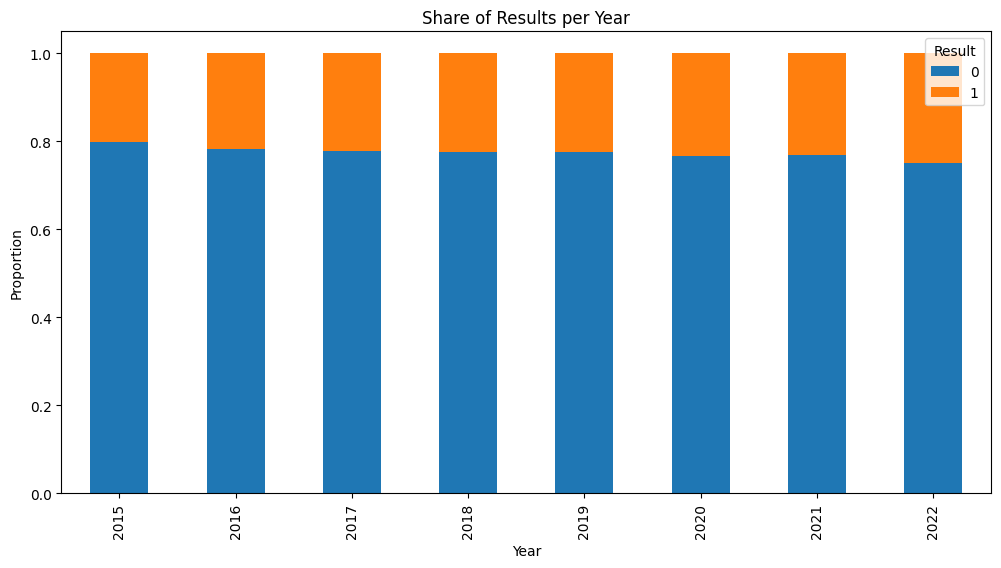

In [37]:
# share of each result in each year (each row adds up to 1)
import matplotlib.pyplot as plt
ct = pd.crosstab(df['Inspection Date'].dt.year, df['Fail'])
year_share = ct.divide(ct.sum(axis='columns'), axis='rows')
year_share.plot.bar(stacked=True, figsize=(12, 6))
plt.title('Share of Results per Year')
plt.xlabel('Year')
plt.ylabel('Proportion')
plt.legend(title='Result')
plt.show()

We save only the ID and the new columns. At the end of the week this file is joined with Joud's file and the clean file on `Inspection ID`.